In [ ]:
%load_ext autoreload
%autoreload 2
import numpy as np
import matplotlib.pyplot as plt
import plot_params

# ==============================================================================

from config import SEED, FIGURES_PATH, RESULTS_PATH, DATA_PATH
from Data.data import load_mnist, train_val_split, one_hot, to_column
from Machine.network import NeuralNetwork
from Machine.optimizers import train
from Machine.metrics import mse_score, accuracy, confusion_matrix, precision_recall_f1
import utils as u       # Reused functions from Project 1

RERUN = False   # load saved results when they exist

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part b)** Neural network

</div>

In [8]:
# ----- B1: Data, OLS benchmark ------------------------------------------------
x_train, x_test, y_train, y_test = u.create_dataset()   # Project 1's data
X_tr, X_te = to_column(x_train), to_column(x_test)      # the network wants shape (n, 1)
Y_tr, Y_te = to_column(y_train), to_column(y_test)

# OLS benchmark: best polynomial degree by test MSE
max_deg = 20
ols_mse = np.zeros(max_deg)
for d in range(1, max_deg + 1):
    Xd_tr, Xd_te = u.create_feature_matrix(x_train, x_test, degree=d)
    theta = u.closed_form(Xd_tr, y_train)
    ols_mse[d - 1] = mse_score(y_test, Xd_te @ theta)
best_deg = int(np.argmin(ols_mse)) + 1
print(f"OLS: best degree {best_deg}, test MSE {ols_mse[best_deg - 1]:.4f}")

# validation set from the training data, for choosing learning rates
X_fit, X_val, Y_fit, Y_val = train_val_split(X_tr, Y_tr, val_size=0.25, seed=SEED, stratify=False)

OLS: best degree 17, test MSE 0.0283


best on validation: SGD + RMSprop, gamma = 1.0e-01, val MSE 0.0145


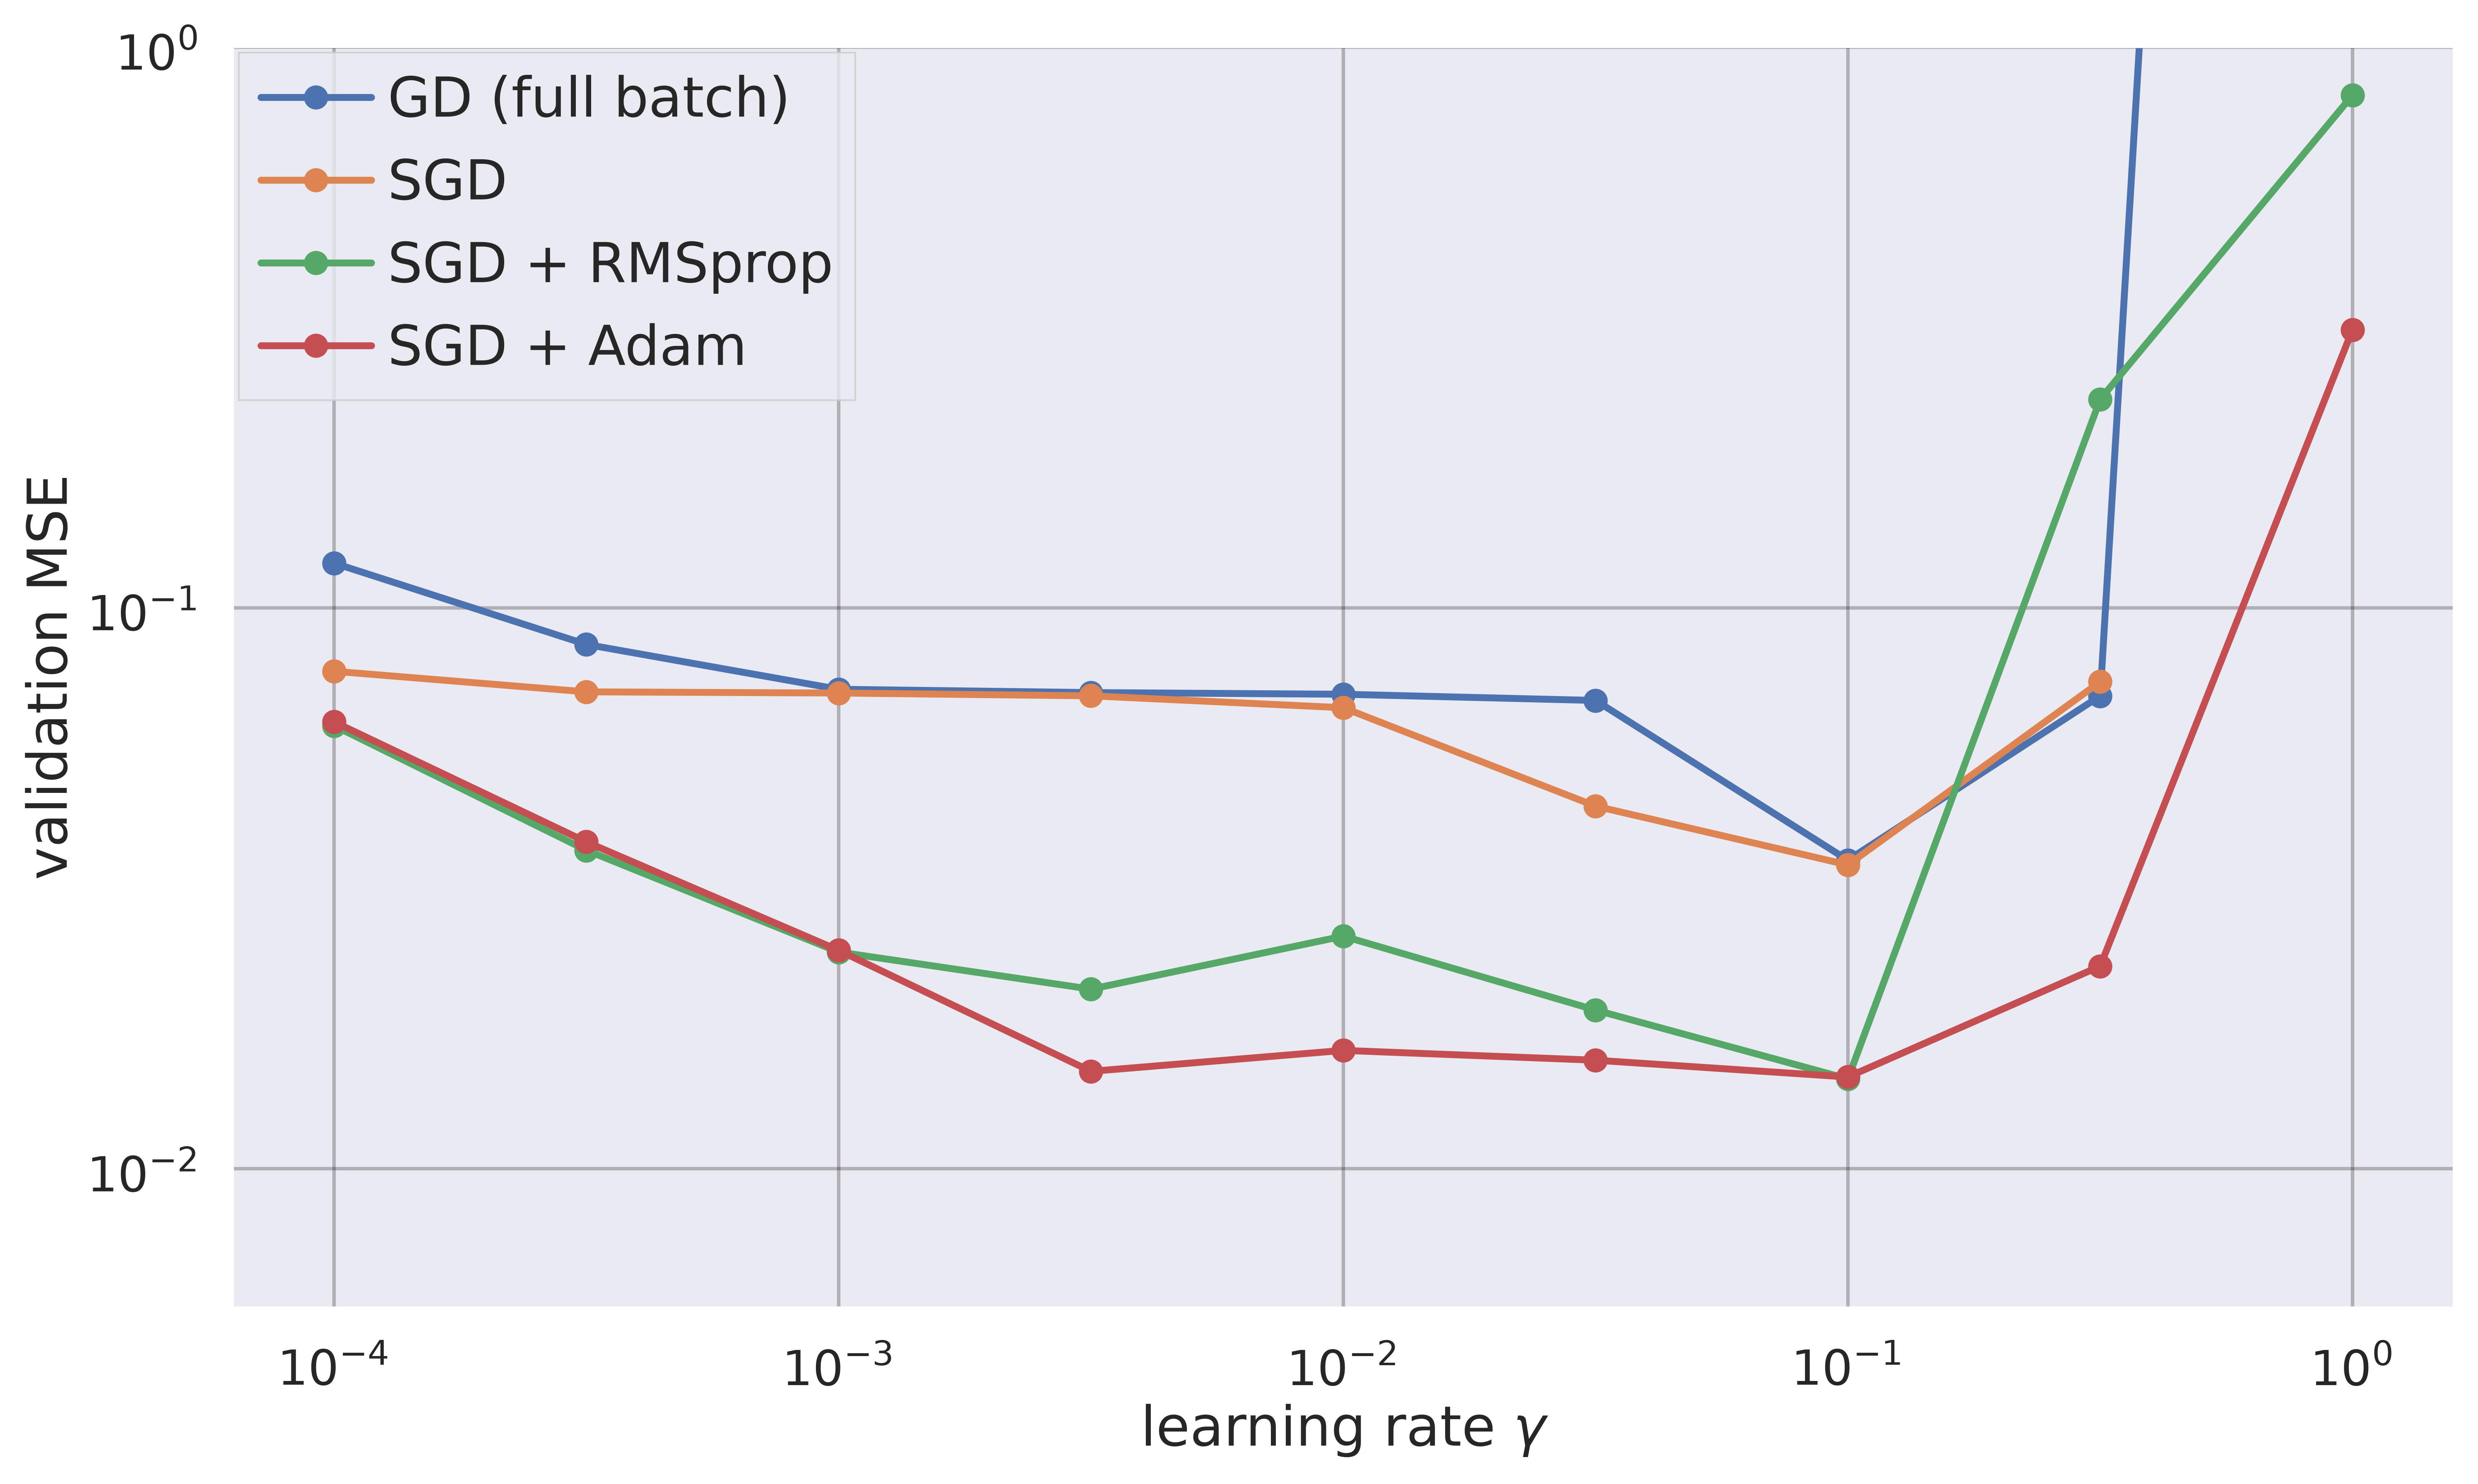

In [ ]:
# ----- B2: Learning rate sweep ------------------------------------------------
VARIANTS = {                        # name: (optimizer, batch size)
    "GD (full batch)": ("plain", None),
    "SGD": ("plain", 10),
    "SGD + RMSprop": ("rmsprop", 10),
    "SGD + Adam": ("adam", 10)
}
gammas = np.geomspace(1e-4, 1.0, 9)
EPOCHS = 1000
sweep_path = RESULTS_PATH / "b_lr_sweep.npz"

if RERUN or not sweep_path.exists():
    val_mse = np.full((len(VARIANTS), len(gammas)), np.nan)
    for i, (method, batch_size) in enumerate(VARIANTS.values()):
        for j, gamma in enumerate(gammas):
            net = NeuralNetwork([1, 50, 1], ["sigmoid", "identity"], "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, X_fit, Y_fit, method=method, gamma=gamma, epochs=EPOCHS,
                      batch_size=batch_size, seed=SEED)
                val_mse[i, j] = mse_score(Y_val, net.predict(X_val))
    np.savez(sweep_path, val_mse=val_mse, gammas=gammas)
else:
    saved = np.load(sweep_path)
    val_mse, gammas = saved["val_mse"], saved["gammas"]
    
names = list(VARIANTS)
best_i, best_j = np.unravel_index(np.nanargmin(val_mse), val_mse.shape)
print(f"best on validation: {names[best_i]}, "
      f"gamma = {gammas[best_j]:.1e}, val MSE {val_mse[best_i, best_j]:.4f}")

fig, ax = plt.subplots(figsize=(10, 6))
for i, name in enumerate(names):
    ax.loglog(gammas, val_mse[i], "o-", label=name)
ax.set_xlabel(r"learning rate $\gamma$")
ax.set_ylabel("validation MSE")
ax.set_ylim(top=1.0)
ax.legend()
plt.savefig(FIGURES_PATH / "B-learning_rate_sweep.pdf")
plt.show()

In [14]:
# ----- B3: Architectures ------------------------------------------------------
ARCHS = {
    "1 x 50":   [1, 50, 1],
    "1 x 500":  [1, 500, 1],
    "2 x 50":   [1, 50, 50, 1],
    "2 x 100":  [1, 100, 100, 1]
}
method, batch_size = list(VARIANTS.values())[best_i]   # best optimizer from B2

# dense grid on the standardsized coordinates, to draw smooth curves
x_raw, y_raw = u.create_dataset(split=False, rescale=False)
xg = np.linspace(-1, 1, 400)
xg_std = (xg - x_raw.mean()) / x_raw.std()

arch_path = RESULTS_PATH / "b_architectures.npz"
if RERUN or not arch_path.exists():
    best_gammas, train_mse, test_mse, curves = [], [], [], []
    for sizes in ARCHS.values():
        acts = ["sigmoid"] * (len(sizes) - 2) + ["identity"]
        
        # 1: choose gamma for this architecture on the validation set
        scores = []
        for g in gammas:
            net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
            with np.errstate(all="ignore"):
                train(net, X_fit, Y_fit, method=method, gamma=g, epochs=EPOCHS,
                      batch_size=batch_size, seed=SEED)
            scores.append(mse_score(Y_val, net.predict(X_val)))
        g_best = gammas[np.nanargmin(scores)]
        
        # 2: retain on full training set with that gamma, then look at test once
        net = NeuralNetwork(sizes, acts, "mse", seed=SEED)
        train(net, X_tr, Y_tr, method=method, gamma=g_best, epochs=EPOCHS,
              batch_size=batch_size, seed=SEED)
        best_gammas.append(g_best)
        train_mse.append(mse_score(Y_tr, net.predict(X_tr)))
        test_mse.append(mse_score(Y_te, net.predict(X_te)))
        curves.append(net.predict(to_column(xg_std)).ravel())
    best_gammas, train_mse, test_mse, curves = map(np.array, (best_gammas, train_mse, test_mse, curves))
    np.savez(arch_path, best_gammas=best_gammas, train_mse=train_mse, test_mse=test_mse, curves=curves)
else:
    saved = np.load(arch_path)
    best_gammas, train_mse, test_mse, curves = (saved[k] for k in ("best_gammas", "train_mse", "test_mse", "curves"))

# OLS fit with the best degree, on the same grid
Xd_tr = u.create_feature_matrix(x_train, degree=best_deg)
theta = u.closed_form(Xd_tr, y_train)
ols_curve = u.create_feature_matrix(xg_std, degree=best_deg) @ theta
ols_train = mse_score(y_train, Xd_tr @ theta)

model             gamma  train MSE  test MSE
OLS deg 17                  0.0275    0.0283
NN 1 x 50       1.0e-01     0.0148    0.0154
NN 1 x 500      1.0e-01     0.0125    0.0153
NN 2 x 50       1.0e-03     0.0112    0.0112
NN 2 x 100      1.0e-02     0.0100    0.0187


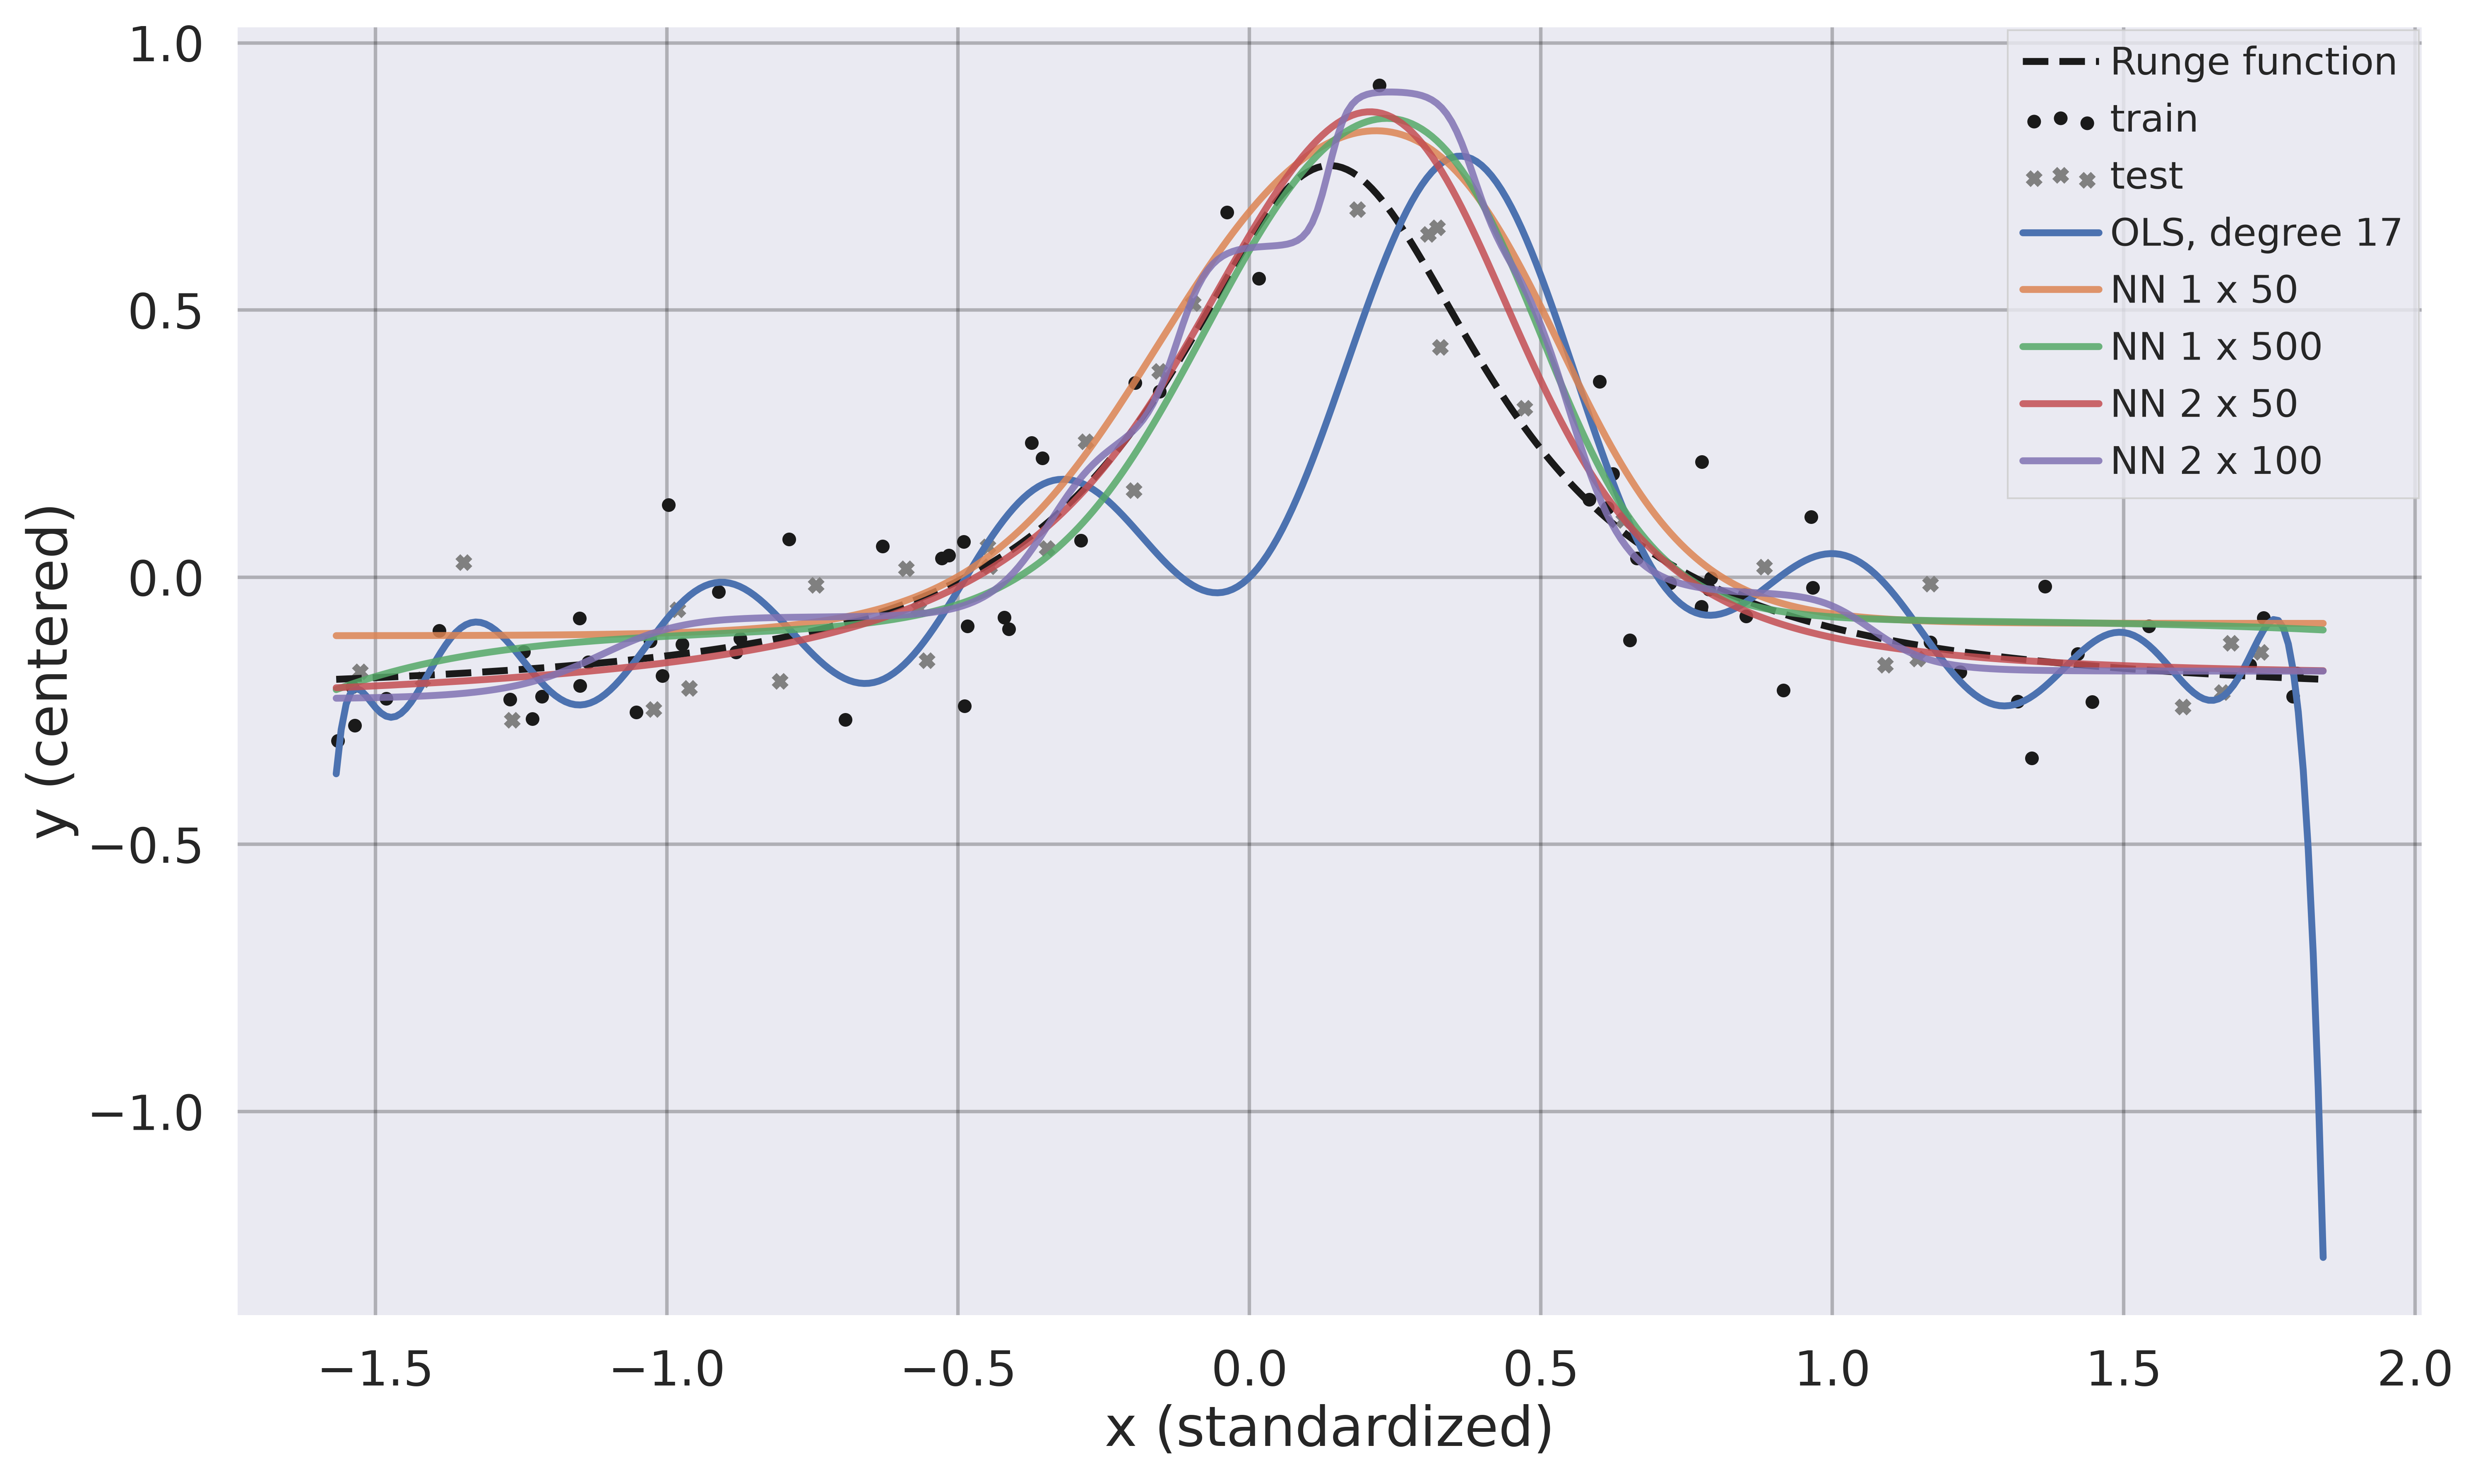

In [22]:
# ----- B4: Results ------------------------------------------------------------
print(f"{'model':<14}{'gamma':>9}{'train MSE':>11}{'test MSE':>10}")
print(f"{'OLS deg ' + str(best_deg):<14}{'':>9}{ols_train:>11.4f}{ols_mse[best_deg - 1]:>10.4f}")
for name, g, tr, te in zip(ARCHS, best_gammas, train_mse, test_mse):
    print(f"{'NN ' + name:<14}{g:>9.1e}{tr:>11.4f}{te:>10.4f}")
    
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(xg_std, 1 / (1 + 25 * xg**2) - y_raw.mean(), "k--", label="Runge function")
ax.scatter(x_train, y_train, s=12, color="k", label="train")
ax.scatter(x_test, y_test, s=12, color="gray", label="test", marker="x")
ax.plot(xg_std, ols_curve, label=f"OLS, degree {best_deg}")
for name, curve in zip(ARCHS, curves):
    ax.plot(xg_std, curve, label=f"NN {name}", alpha=0.85)
ax.set_xlabel("x (standardized)")
ax.set_ylabel("y (centered)")
ax.legend(loc="upper right", fontsize=11)
plt.savefig(FIGURES_PATH / "B-NN_vs_OLS_fits.pdf")
plt.show()

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part c)** Activation functions and depths

</div>

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part d)** Different norms

</div>

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part e)** Classification analysis

</div>

<div style="background-color:#F0DAE2; color:#823C55; border-radius:12px; padding:16px; width:90%;">

**Part f)** Various algorithms

</div>